# UTS Analitika Data — Prediksi Risiko Kegagalan Panen
**Algoritma:** Decision Tree & Random Forest | **Target:** `Status_Risiko_Panen` (1 = Berisiko Gagal Panen)

Alur: Soal 01 (tujuan) → Soal 02 (data) → Soal 03 (skenario) → Soal 04 (model) → Soal 05 (evaluasi).
Jalankan sel dari atas ke bawah (Runtime → Run all). Semua proses memakai `random_state=42` sehingga hasil dapat direproduksi.

## SOAL 01 — Tujuan dan Kebutuhan Pemodelan
**a. Masalah & stakeholder.** Gagal panen menimbulkan kerugian bagi petani dan mengancam pasokan pangan. Stakeholder: petani/kelompok tani, penyuluh pertanian, dinas pertanian, dan penyedia asuransi/pembiayaan pertanian. Keputusan yang didukung: menentukan lahan/petani prioritas untuk pendampingan, distribusi benih/pupuk/irigasi, serta penilaian risiko asuransi.

**b. Business objective.** Mengidentifikasi lebih dini lahan yang berisiko gagal panen sehingga intervensi (penyuluhan, perbaikan irigasi, benih unggul, pengendalian hama) dapat difokuskan, dan kerugian panen berkurang.

**c. Analytical objective.** Membangun model klasifikasi biner (Decision Tree & Random Forest) untuk memprediksi `Status_Risiko_Panen`. Pertanyaan analitik: (1) faktor apa yang paling memengaruhi risiko? (2) seberapa akurat model mendeteksi lahan berisiko (recall tinggi)? (3) apakah feature selection, feature engineering, balancing, cross validation, dan tuning meningkatkan kinerja?

In [1]:
# ============ 1. IMPORT LIBRARY ============
# pandas/numpy: olah data | matplotlib/seaborn: visualisasi | sklearn: model & evaluasi
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, warnings
from sklearn.model_selection import train_test_split, StratifiedKFold, ParameterGrid
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, SelectFromModel, mutual_info_classif
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.utils import resample
warnings.filterwarnings('ignore'); sns.set_style('whitegrid')
RS = 42   # random seed supaya hasil selalu sama

## SOAL 02 — Menelaah, Memvalidasi, dan Menyiapkan Data
### 2a. Menelaah karakteristik data

In [2]:
# ============ 2. LOAD DATASET ============
# Di Colab: pilih file B01_Prediksi_Risiko_Kegagalan_Panen.csv saat diminta upload
PATH = 'B01_Prediksi_Risiko_Kegagalan_Panen.csv'
try:
    from google.colab import files
    up = files.upload(); PATH = list(up.keys())[0]
except ImportError:
    pass
df = pd.read_csv(PATH, encoding='utf-8-sig')
TARGET = 'Status_Risiko_Panen'
print('Ukuran data (baris, kolom):', df.shape)
display(df.head())

Saving B01_Prediksi_Risiko_Kegagalan_Panen.csv to B01_Prediksi_Risiko_Kegagalan_Panen.csv
Ukuran data (baris, kolom): (500, 15)


,Jenis_Komoditas,Luas_Lahan_ha,Jenis_Tanah,pH_Tanah,Curah_Hujan_mm_bulan,Suhu_Rata_Rata_C,Kelembapan_Udara_persen,Ketersediaan_Irigasi,Kualitas_Benih,Frekuensi_Pemupukan_per_musim,Penggunaan_Pestisida,Serangan_Hama,Serangan_Penyakit,Pengalaman_Petani_tahun,Status_Risiko_Panen
0,Padi,1.22,Aluvial,6.0,298.9,26.1,40.0,Terbatas,Sedang,0.0,Tidak Sesuai,Ringan,Ringan,7.0,Tidak Berisiko
1,Cabai,2.20,Andosol,7.4,275.9,27.3,49.0,Terbatas,Sedang,6.0,Sesuai Anjuran,Ringan,Sedang,12.0,Tidak Berisiko
2,Jagung,2.33,Andosol,6.4,35.0,28.1,52.0,Memadai,Unggul,1.0,Tidak Menggunakan,Tidak Ada,Ringan,20.0,Berisiko Gagal Panen
3,Cabai,1.82,Regosol,7.9,NaN,30.0,44.0,Terbatas,Sedang,7.0,Sesuai Anjuran,Sedang,Ringan,20.0,Tidak Berisiko
4,Kedelai,0.98,Aluvial,7.5,147.4,23.5,87.0,Terbatas,Unggul,1.0,Tidak Sesuai,Tidak Ada,Ringan,31.0,Tidak Berisiko


**Cara membaca:** `Ukuran data` = jumlah observasi & atribut. `head()` menampilkan 5 baris pertama untuk memastikan data terbaca benar (kolom pertama tidak rusak, nilai kategori terbaca).

In [3]:
# ============ 3. STRUKTUR, TIPE DATA, STATISTIK DESKRIPTIF ============
df.info()                                   # tipe data & jumlah nilai non-null per kolom
display(df.describe().T.round(2))           # statistik atribut numerik
display(df.describe(include='object').T)    # atribut kategorikal: jumlah kategori (unique), modus (top)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Jenis_Komoditas                489 non-null    object 
 1   Luas_Lahan_ha                  483 non-null    float64
 2   Jenis_Tanah                    485 non-null    object 
 3   pH_Tanah                       489 non-null    float64
 4   Curah_Hujan_mm_bulan           479 non-null    float64
 5   Suhu_Rata_Rata_C               489 non-null    float64
 6   Kelembapan_Udara_persen        488 non-null    float64
 7   Ketersediaan_Irigasi           496 non-null    object 
 8   Kualitas_Benih                 490 non-null    object 
 9   Frekuensi_Pemupukan_per_musim  487 non-null    float64
 10  Penggunaan_Pestisida           490 non-null    object 
 11  Serangan_Hama                  494 non-null    object 
 12  Serangan_Penyakit              487 non-null    obj

,count,mean,std,min,25%,50%,75%,max
Luas_Lahan_ha,483.0,1.54,1.26,0.1,0.76,1.27,2.03,16.23
pH_Tanah,489.0,6.25,1.04,3.6,5.60,6.20,6.80,19.06
Curah_Hujan_mm_bulan,479.0,222.78,101.12,20.0,156.45,223.20,282.50,1114.84
Suhu_Rata_Rata_C,489.0,27.98,2.49,20.0,26.30,27.90,29.80,34.70
Kelembapan_Udara_persen,488.0,67.80,16.65,40.0,53.75,68.00,83.00,95.00
Frekuensi_Pemupukan_per_musim,487.0,3.49,2.25,0.0,1.00,3.00,5.00,7.00
Pengalaman_Petani_tahun,489.0,20.36,11.51,1.0,10.00,20.00,30.00,40.00


,count,unique,top,freq
Jenis_Komoditas,489,5,Cabai,102
Jenis_Tanah,485,5,Andosol,103
Ketersediaan_Irigasi,496,3,Memadai,256
Kualitas_Benih,490,3,Unggul,227
Penggunaan_Pestisida,490,3,Sesuai Anjuran,318
Serangan_Hama,494,4,Ringan,149
Serangan_Penyakit,487,4,Tidak Ada,199
Status_Risiko_Panen,500,2,Tidak Berisiko,350


**Cara membaca:** pada `info()`, jumlah non-null < 500 berarti ada *missing value*. Pada `describe()` bandingkan `min`/`max` dengan `mean`/`50%`: nilai `max` yang jauh lebih besar (mis. pH 19, curah hujan > 1000 mm) menandakan nilai tidak valid / ekstrem.

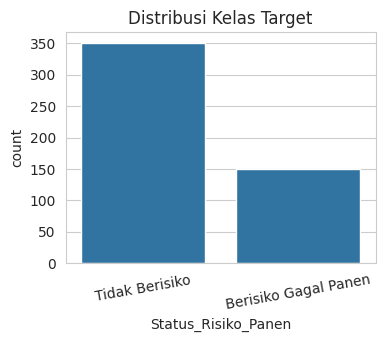

Status_Risiko_Panen
Tidak Berisiko          0.7
Berisiko Gagal Panen    0.3
Name: proportion, dtype: float64


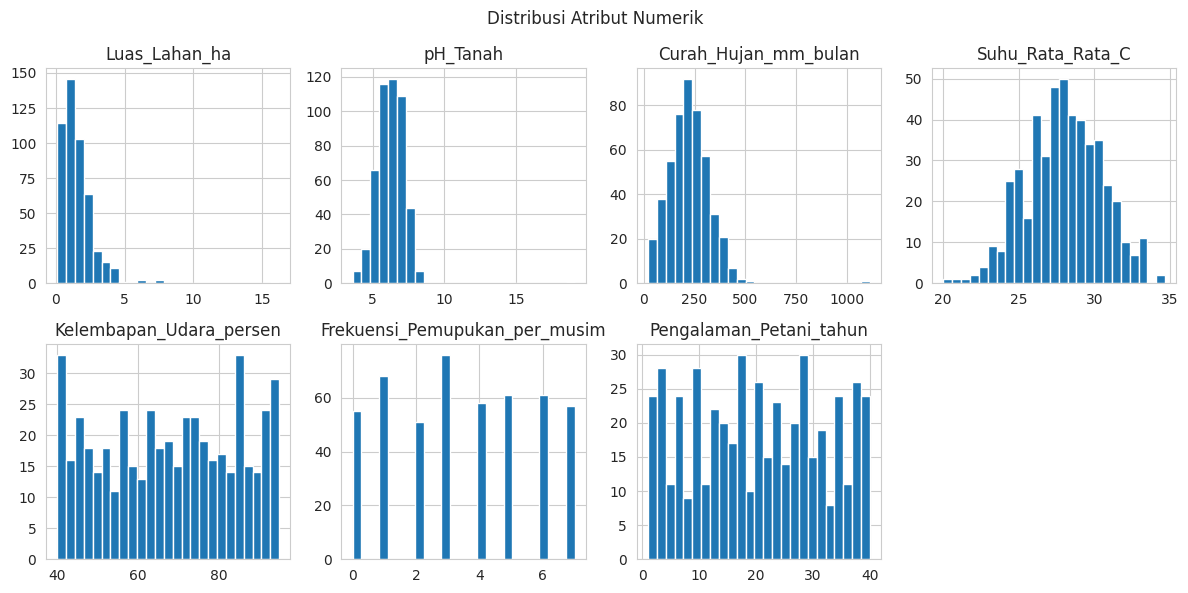

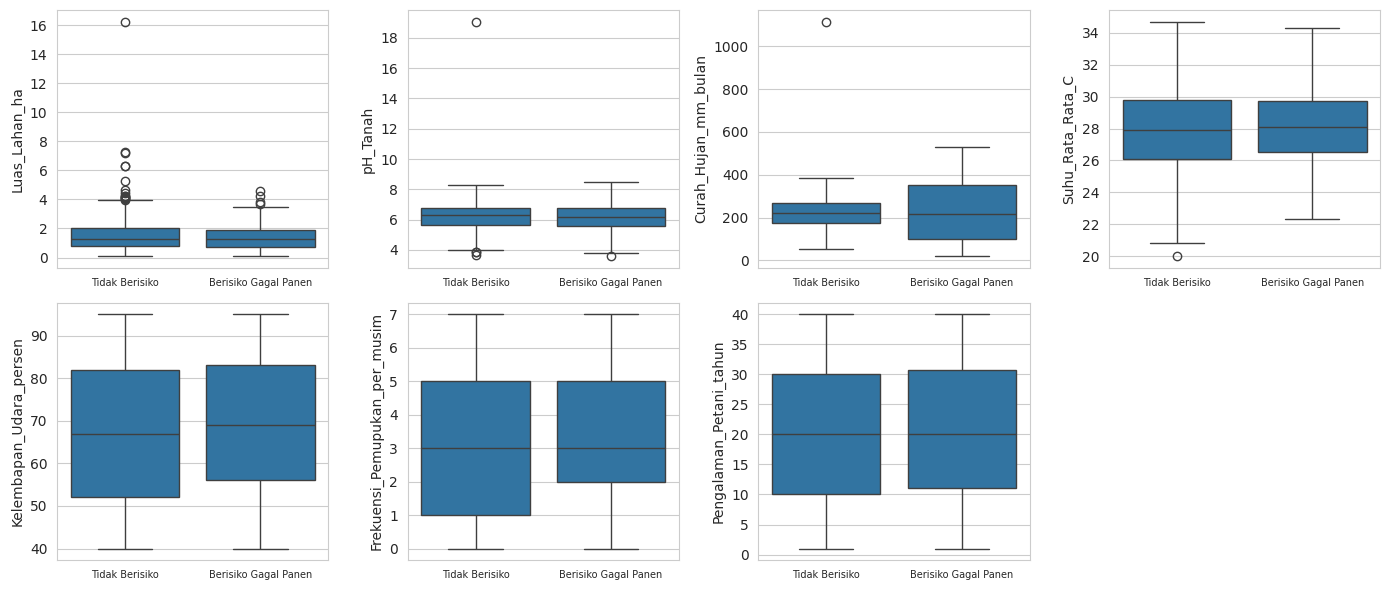

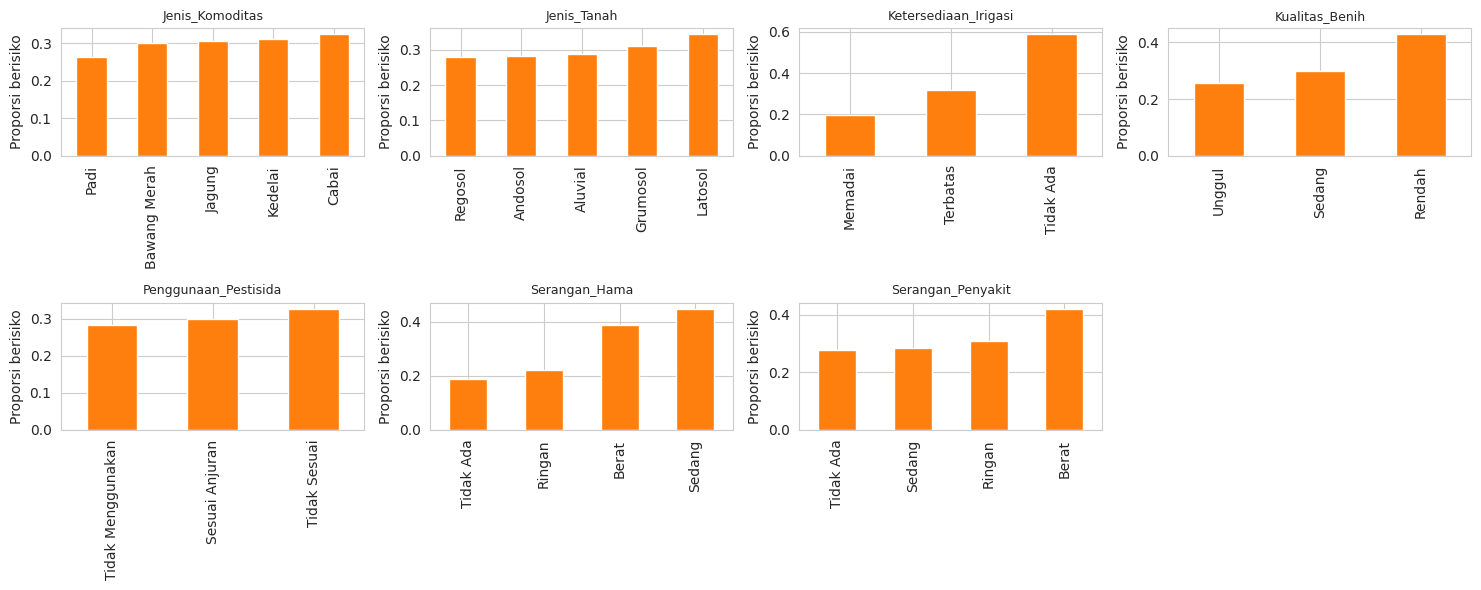

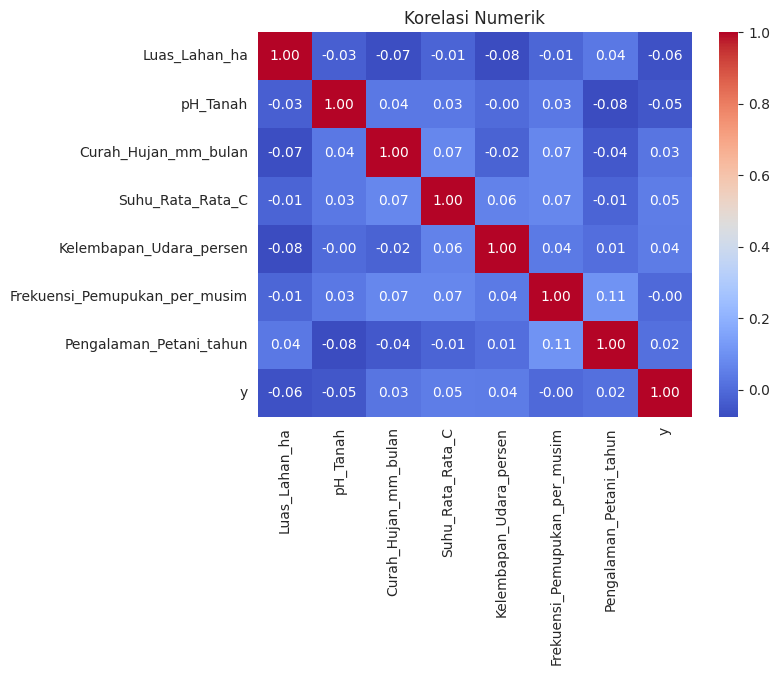

In [4]:
# ============ 4. VISUALISASI EKSPLORASI ============
df['y'] = (df[TARGET] == 'Berisiko Gagal Panen').astype(int)   # 1 = berisiko (kelas positif)
num_cols = ['Luas_Lahan_ha','pH_Tanah','Curah_Hujan_mm_bulan','Suhu_Rata_Rata_C',
            'Kelembapan_Udara_persen','Frekuensi_Pemupukan_per_musim','Pengalaman_Petani_tahun']
cat_cols = ['Jenis_Komoditas','Jenis_Tanah','Ketersediaan_Irigasi','Kualitas_Benih',
            'Penggunaan_Pestisida','Serangan_Hama','Serangan_Penyakit']

# (a) distribusi target
plt.figure(figsize=(4,3)); sns.countplot(x=TARGET, data=df); plt.title('Distribusi Kelas Target'); plt.xticks(rotation=10); plt.show()
print(df[TARGET].value_counts(normalize=True).round(3))

# (b) histogram atribut numerik
df[num_cols].hist(bins=25, figsize=(12,6), layout=(2,4)); plt.suptitle('Distribusi Atribut Numerik'); plt.tight_layout(); plt.show()

# (c) boxplot numerik per kelas target
fig, ax = plt.subplots(2,4, figsize=(14,6))
for a,c in zip(ax.ravel(), num_cols): sns.boxplot(x=TARGET, y=c, data=df, ax=a); a.set_xlabel(''); a.tick_params(axis='x', labelsize=7)
ax.ravel()[-1].axis('off'); plt.tight_layout(); plt.show()

# (d) tingkat risiko per kategori (dasar hipotesis)
fig, ax = plt.subplots(2,4, figsize=(15,6))
for a,c in zip(ax.ravel(), cat_cols):
    df.groupby(c)['y'].mean().sort_values().plot.bar(ax=a, color='tab:orange'); a.set_title(c, fontsize=9); a.set_ylabel('Proporsi berisiko'); a.set_xlabel('')
ax.ravel()[-1].axis('off'); plt.tight_layout(); plt.show()

# (e) korelasi numerik dengan target
plt.figure(figsize=(7,5)); sns.heatmap(df[num_cols+['y']].corr(), annot=True, fmt='.2f', cmap='coolwarm'); plt.title('Korelasi Numerik'); plt.show()

**Cara membaca:**
- *Distribusi target*: kelas tidak seimbang (~70% Tidak Berisiko vs ~30% Berisiko) → akurasi saja menyesatkan, perlu recall & F1 serta skenario *balancing*.
- *Histogram*: bentuk sebaran & outlier (batang jauh di ujung).
- *Boxplot*: jika kotak dua kelas bergeser/tidak tumpang tindih, atribut tersebut membedakan kelas.
- *Bar tingkat risiko*: semakin tinggi batang, semakin besar proporsi gagal panen pada kategori itu.
- *Heatmap*: nilai mendekati ±1 = korelasi kuat; di sini sebagian besar korelasi numerik lemah sehingga atribut kategorikal diduga lebih berpengaruh.

In [5]:
# ============ 5. UJI HIPOTESIS AWAL (angka pendukung) ============
# H1: irigasi tidak ada/terbatas -> risiko lebih tinggi
# H2: serangan hama & penyakit berat -> risiko lebih tinggi
# H3: benih berkualitas rendah -> risiko lebih tinggi
# H4: petani berpengalaman lebih rendah risikonya
# H5: curah hujan ekstrem (<100 atau >350 mm/bulan) -> risiko lebih tinggi
for c in ['Ketersediaan_Irigasi','Serangan_Hama','Serangan_Penyakit','Kualitas_Benih']:
    print(f'--- Proporsi berisiko menurut {c}'); print(df.groupby(c)['y'].mean().round(3).to_string())
print('--- Proporsi berisiko menurut kelompok curah hujan (mm/bulan)'); print(df.groupby(pd.cut(df.Curah_Hujan_mm_bulan,[0,100,350,2000]))['y'].mean().round(3).to_string())
print('--- Rata-rata pengalaman petani per kelas'); print(df.groupby(TARGET)['Pengalaman_Petani_tahun'].mean().round(2).to_string())

--- Proporsi berisiko menurut Ketersediaan_Irigasi
Ketersediaan_Irigasi
Memadai      0.195
Terbatas     0.319
Tidak Ada    0.588
--- Proporsi berisiko menurut Serangan_Hama
Serangan_Hama
Berat        0.390
Ringan       0.221
Sedang       0.449
Tidak Ada    0.189
--- Proporsi berisiko menurut Serangan_Penyakit
Serangan_Penyakit
Berat        0.421
Ringan       0.309
Sedang       0.286
Tidak Ada    0.276
--- Proporsi berisiko menurut Kualitas_Benih
Kualitas_Benih
Rendah    0.429
Sedang    0.301
Unggul    0.256
--- Proporsi berisiko menurut kelompok curah hujan (mm/bulan)
Curah_Hujan_mm_bulan
(0, 100]       0.729
(100, 350]     0.191
(350, 2000]    0.841
--- Rata-rata pengalaman petani per kelas
Status_Risiko_Panen
Berisiko Gagal Panen    20.62
Tidak Berisiko          20.24


**Cara membaca:** bandingkan proporsi antar kategori. Jika kategori 'buruk' (Tidak Ada, Berat, Rendah) memiliki proporsi berisiko jauh lebih besar, hipotesis H1–H3 didukung data. Untuk H5, kelompok hujan <100 atau >350 mm yang risikonya jauh lebih tinggi mendukung hipotesis; H4 (pengalaman) tampak tidak didukung karena rata-rata kedua kelas hampir sama. Hipotesis ini diuji formal oleh model melalui *feature importance* pada Soal 05.

### 2b. Memvalidasi data

In [6]:
# ============ 6. VALIDASI DATA ============
miss = df.drop(columns='y').isna().sum(); print('Missing value per kolom:'); print(miss[miss>0].to_string())
print('Total missing:', int(miss.sum()), '| baris dengan >=1 missing:', int(df.drop(columns='y').isna().any(axis=1).sum()))
print('Baris duplikat:', int(df.drop(columns='y').duplicated().sum()))
print('Nilai pH di luar 0-14:', df.loc[(df.pH_Tanah<=0)|(df.pH_Tanah>14),'pH_Tanah'].tolist())
print('Nilai negatif pada numerik:', int((df[num_cols]<0).sum().sum()))
# konsistensi penulisan kategori (spasi/huruf besar-kecil)
for c in cat_cols: print(c, '->', sorted(df[c].dropna().unique()))
# outlier (aturan IQR)
q1,q3 = df[num_cols].quantile(.25), df[num_cols].quantile(.75); iqr=q3-q1
out = ((df[num_cols] < q1-1.5*iqr) | (df[num_cols] > q3+1.5*iqr)).sum(); print('Jumlah outlier IQR:'); print(out.to_string())
# keterwakilan
print('Sebaran komoditas:'); print(df.Jenis_Komoditas.value_counts().to_string())

Missing value per kolom:
Jenis_Komoditas                  11
Luas_Lahan_ha                    17
Jenis_Tanah                      15
pH_Tanah                         11
Curah_Hujan_mm_bulan             21
Suhu_Rata_Rata_C                 11
Kelembapan_Udara_persen          12
Ketersediaan_Irigasi              4
Kualitas_Benih                   10
Frekuensi_Pemupukan_per_musim    13
Penggunaan_Pestisida             10
Serangan_Hama                     6
Serangan_Penyakit                13
Pengalaman_Petani_tahun          11
Total missing: 165 | baris dengan >=1 missing: 146
Baris duplikat: 15
Nilai pH di luar 0-14: [19.06]
Nilai negatif pada numerik: 0
Jenis_Komoditas -> ['Bawang Merah', 'Cabai', 'Jagung', 'Kedelai', 'Padi']
Jenis_Tanah -> ['Aluvial', 'Andosol', 'Grumosol', 'Latosol', 'Regosol']
Ketersediaan_Irigasi -> ['Memadai', 'Terbatas', 'Tidak Ada']
Kualitas_Benih -> ['Rendah', 'Sedang', 'Unggul']
Penggunaan_Pestisida -> ['Sesuai Anjuran', 'Tidak Menggunakan', 'Tidak Sesuai']
Sera

**Cara membaca & rekomendasi penanganan:**
| Temuan | Rekomendasi |
|---|---|
| Missing ±2–4% per kolom (acak, tersebar di banyak kolom) | Imputasi (median numerik, modus kategorikal) **di dalam pipeline** agar tanpa leakage; menghapus baris akan membuang banyak data |
| Duplikasi | Hapus (menghindari bias & kebocoran antar train–test) |
| pH > 14 (tidak mungkin secara fisik) | Ubah ke NaN lalu imputasi |
| Outlier hujan/luas lahan | Dipertahankan (mungkin nyata; pohon keputusan tahan outlier) |
| Kelas 70:30, komoditas & tanah relatif merata | Gunakan stratified split, metrik recall/F1, uji balancing |

### 2c. Menentukan objek data & membersihkan data

In [7]:
# ============ 7. PEMBERSIHAN DATA ============
raw = df.drop(columns='y').copy()
d = raw.copy()
for c in d.select_dtypes(exclude='number').columns: d[c] = d[c].str.strip()   # rapikan teks
d = d.drop_duplicates().reset_index(drop=True)                                 # hapus duplikat
d.loc[(d.pH_Tanah<=0)|(d.pH_Tanah>14), 'pH_Tanah'] = np.nan                    # nilai tidak valid -> NaN
# Atribut & observasi: seluruh 14 atribut prediktor relevan dengan faktor agronomi, semua observasi dipakai
# (target tidak ada yang kosong). Imputasi missing dilakukan di pipeline setelah split.
cmp = pd.DataFrame({'Sebelum':[raw.shape[0], raw.isna().sum().sum(), raw.duplicated().sum(), raw.pH_Tanah.max()],
                    'Sesudah':[d.shape[0],   d.isna().sum().sum(),   d.duplicated().sum(),   d.pH_Tanah.max()]},
                   index=['Jumlah baris','Total missing','Duplikat','pH maksimum'])
display(cmp)
d.to_csv('analytical_dataset.csv', index=False)   # dataset analitik hasil pembersihan (disimpan)
print('Distribusi target setelah bersih:'); print(d[TARGET].value_counts().to_string())

,Sebelum,Sesudah
Jumlah baris,500.00,485.0
Total missing,165.00,162.0
Duplikat,15.00,0.0
pH maksimum,19.06,8.5


Distribusi target setelah bersih:
Status_Risiko_Panen
Tidak Berisiko          340
Berisiko Gagal Panen    145


**Cara membaca:** tabel membandingkan kondisi sebelum–sesudah pembersihan. Baris berkurang karena 15 duplikat dihapus (total missing ikut turun karena sebagian duplikat memuat NaN), dan pH tidak valid (19.06) menjadi NaN untuk diimputasi. File `analytical_dataset.csv` adalah analytical dataset untuk tahap pemodelan.

In [8]:
# ============ 8. PEMBAGIAN DATA 80:20 (STRATIFIED) ============
X = d.drop(columns=TARGET); y = (d[TARGET]=='Berisiko Gagal Panen').astype(int).values
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print('Train:', Xtr.shape, '| Test:', Xte.shape, '| proporsi berisiko train/test:', ytr.mean().round(3), yte.mean().round(3))

Train: (388, 14) | Test: (97, 14) | proporsi berisiko train/test: 0.299 0.299


**Cara membaca:** data uji (20%) disisihkan sebelum preprocessing apa pun. Proporsi kelas pada train & test hampir sama karena `stratify`.

### 2d. Mengkonstruksi data (encoding, rekayasa fitur)

In [9]:
# ============ 9. KELAS PREPROCESSING (fit hanya pada data latih -> tanpa data leakage) ============
ORD = {'Ketersediaan_Irigasi':{'Tidak Ada':0,'Terbatas':1,'Memadai':2},   # ordinal
       'Kualitas_Benih':{'Rendah':0,'Sedang':1,'Unggul':2},
       'Serangan_Hama':{'Tidak Ada':0,'Ringan':1,'Sedang':2,'Berat':3},
       'Serangan_Penyakit':{'Tidak Ada':0,'Ringan':1,'Sedang':2,'Berat':3}}
NOM = ['Jenis_Komoditas','Jenis_Tanah','Penggunaan_Pestisida']             # nominal -> one-hot
NUM = num_cols

class Prep:
    '''Imputasi (median/modus dari data latih) + encoding + (opsional) feature engineering.
    Normalisasi tidak diperlukan karena Decision Tree & Random Forest tidak sensitif skala.'''
    def __init__(self, fe=False): self.fe = fe
    def fit(self, X):
        self.med = X[NUM].median(); self.mode = X[list(ORD)+NOM].mode().iloc[0]
        self.cols = list(self._t(X).columns); return self
    def _t(self, X):
        Z = X.copy(); Z[NUM] = Z[NUM].fillna(self.med); Z[list(ORD)+NOM] = Z[list(ORD)+NOM].fillna(self.mode)
        for c,m in ORD.items(): Z[c] = Z[c].map(m)
        if self.fe:   # rekayasa fitur berbasis domain pertanian
            Z['Skor_OPT']       = Z.Serangan_Hama + Z.Serangan_Penyakit                      # beban hama+penyakit
            Z['Indeks_Sarana']  = Z.Ketersediaan_Irigasi + Z.Kualitas_Benih                  # dukungan irigasi+benih
            Z['pH_Optimal']     = Z.pH_Tanah.between(5.5, 7.5).astype(int)                   # pH ideal
            Z['Pupuk_per_Ha']   = Z.Frekuensi_Pemupukan_per_musim / Z.Luas_Lahan_ha          # intensitas pupuk
            Z['Hujan_Ekstrem']  = ((Z.Curah_Hujan_mm_bulan<100)|(Z.Curah_Hujan_mm_bulan>350)).astype(int)
        return pd.get_dummies(Z, columns=NOM, dtype=int)
    def transform(self, X): return self._t(X).reindex(columns=self.cols, fill_value=0)

# evaluasi fitur hasil konstruksi (hanya pada data latih)
P = Prep(fe=True).fit(Xtr); Ztr = P.transform(Xtr)
new = ['Skor_OPT','Indeks_Sarana','pH_Optimal','Pupuk_per_Ha','Hujan_Ekstrem']
print('Jumlah fitur setelah encoding+FE:', Ztr.shape[1], '(tanpa FE:', Prep().fit(Xtr).transform(Xtr).shape[1], ')')
print('Korelasi fitur baru dengan target (data latih):'); print(Ztr[new].apply(lambda s: np.corrcoef(s, ytr)[0,1]).round(3).to_string())

Jumlah fitur setelah encoding+FE: 29 (tanpa FE: 24 )
Korelasi fitur baru dengan target (data latih):
Skor_OPT         0.216
Indeks_Sarana   -0.255
pH_Optimal       0.024
Pupuk_per_Ha    -0.000
Hujan_Ekstrem    0.491


**Cara membaca:** fitur bertambah dari 24 (tanpa FE) menjadi 29 (dengan FE). Korelasi positif = makin tinggi nilainya makin berisiko; negatif = makin protektif. Fitur dengan |korelasi| lebih besar dari atribut mentah menunjukkan FE bermanfaat (mis. `Hujan_Ekstrem`).

## SOAL 03 — Skenario Model dan Pengujian
**Asumsi data:** (1) atribut agronomi (irigasi, benih, hama, penyakit) memiliki hubungan non-linear dan interaksi dengan risiko; (2) kelas tidak seimbang 70:30; (3) data mengandung missing & outlier acak; (4) ±388 data latih cukup untuk model berbasis pohon, bukan deep learning.
**Teknik kandidat:** Logistic Regression, Naive Bayes, SVM, Decision Tree, Random Forest. **Dipilih:** Decision Tree (mudah diinterpretasi, aturan if-then untuk penyuluh) dan Random Forest (ensemble, lebih stabil, tahan outlier & overfitting) sebagai pembanding.
**Pengujian:** percentage split 80:20 (data 485 baris → cukup data uji ±97 baris) dan Stratified 5-fold cross validation (estimasi stabil pada data kecil).
**Metrik:** accuracy, precision, recall, F1 (kelas positif = Berisiko). Recall diprioritaskan karena lahan berisiko yang terlewat lebih merugikan.
**Kriteria sukses (ditetapkan sebelum modeling):** Accuracy ≥ 0.75 (di atas baseline mayoritas 0.70), Recall ≥ 0.65, F1 ≥ 0.65, dan selisih F1 train–test ≤ 0.10 (tidak overfit).

In [10]:
# ============ 10. DEFINISI SKENARIO (sesuai format Google Sheets) ============
# (feature_selection, feature_engineering, balancing, cross_validation)
SC = [(None,0,None,0), (None,0,None,5),                 # 1-2   baseline murni
      ('kbest',0,None,0), ('kbest',0,None,5),           # 3-4   + feature selection
      ('kbest',1,None,0), ('kbest',1,None,5),           # 5-6   + feature engineering
      (None,0,'ros',0),   (None,0,'ros',5),             # 7-8   + balancing saja
      ('kbest',1,'ros',0),('kbest',1,'ros',5),          # 9-10  semua (SelectKBest + Random Over Sampling)
      ('sfm',1,'cw',0),   ('sfm',1,'cw',5)]             # 11-12 semua (SelectFromModel + class_weight)
SEL = {None:'tidak','kbest':'ya (SelectKBest MI, k=10)','sfm':'ya (SelectFromModel RF, median)'}
BAL = {None:'tidak','ros':'ya (Random OverSampling)','cw':'ya (class_weight=balanced)'}
# Grid hyperparameter (skenario 13-24 = skenario 1-12 + tuning)
GRID = {'DT': {'criterion':['gini','entropy'], 'max_depth':[3,5,7,None], 'min_samples_leaf':[1,5,10]},
        'RF': {'n_estimators':[100,200], 'max_depth':[8,None], 'min_samples_leaf':[1,3]}}

## SOAL 04 — Membangun dan Menguji Model
**Parameter baseline:** DT → default sklearn (`criterion=gini`, `max_depth=None`, `min_samples_leaf=1`); RF → `n_estimators=100`, `max_depth=None`, `min_samples_leaf=1`; `random_state=42`. Tuning memakai Grid Search dengan 5-fold CV pada data latih, skor F1 kelas berisiko.

In [11]:
# ============ 11. PIPELINE MODEL (semua langkah di-fit hanya pada data latih/fold-latih) ============
def metrics(yt, yp):
    return [accuracy_score(yt,yp), precision_score(yt,yp,zero_division=0), recall_score(yt,yp), f1_score(yt,yp)]

class Pipe:
    def __init__(s, name, fe, sel, bal, hp=None): s.name,s.fe,s.sel,s.bal,s.hp = name,fe,sel,bal,hp or {}
    def _model(s):
        cw = 'balanced' if s.bal=='cw' else None
        if s.name=='DT': return DecisionTreeClassifier(random_state=RS, class_weight=cw, **s.hp)
        return RandomForestClassifier(random_state=RS, class_weight=cw, n_jobs=-1, **s.hp)
    def fit(s, X, y):
        s.p = Prep(s.fe).fit(X); Z = s.p.transform(X)
        if s.sel=='kbest':   m = SelectKBest(lambda a,b: mutual_info_classif(a,b,random_state=RS), k=10).fit(Z,y)
        elif s.sel=='sfm':   m = SelectFromModel(RandomForestClassifier(100,random_state=RS), threshold='median').fit(Z,y)
        s.keep = list(Z.columns[m.get_support()]) if s.sel else list(Z.columns)   # fitur terpilih
        Z = Z[s.keep]
        if s.bal=='ros':      # oversampling HANYA pada data latih
            Zy = Z.assign(_y=y); mn = Zy[Zy._y==1]; mj = Zy[Zy._y==0]
            Zy = pd.concat([mj, resample(mn, replace=True, n_samples=len(mj), random_state=RS)]); Z, y = Zy.drop(columns='_y'), Zy._y.values
        s.m = s._model().fit(Z, y); return s
    def predict(s, X): return s.m.predict(s.p.transform(X)[s.keep])

def oof_pred(mk, X, y):
    '''prediksi out-of-fold dengan Stratified 5-fold (dipakai untuk evaluasi CV & tuning)'''
    pr = np.zeros(len(y), int)
    for a,b in StratifiedKFold(5, shuffle=True, random_state=RS).split(X,y):
        pr[b] = mk().fit(X.iloc[a], y[a]).predict(X.iloc[b])
    return pr

def run(name, sc, tune):
    sel, fe, bal, cv = sc; hp, best = {}, None
    if tune:   # Grid Search 5-fold di data latih
        best = -1
        for g in ParameterGrid(GRID[name]):
            f = f1_score(ytr, oof_pred(lambda: Pipe(name,fe,sel,bal,g), Xtr, ytr))
            if f > best: best, hp = f, g
    mk = lambda: Pipe(name,fe,sel,bal,hp)
    final = mk().fit(Xtr, ytr)
    tr = metrics(ytr, oof_pred(mk, Xtr, ytr)) if cv else metrics(ytr, final.predict(Xtr))   # evaluasi training
    te = metrics(yte, final.predict(Xte))                                                   # evaluasi testing (data uji murni)
    return tr, te, hp, final

**Catatan evaluasi:** *Evaluasi training* = skor out-of-fold 5-fold CV bila CV = 5-fold, atau skor pada seluruh data latih bila CV = tidak. *Evaluasi testing* = skor pada 20% data uji yang tidak pernah dipakai membangun model.

In [12]:
# ============ 12. EKSEKUSI SELURUH SKENARIO (24 skenario x 2 algoritma) ============
# Skenario 1-12 = baseline (tuning tidak), 13-24 = sama dengan 1-12 + Grid Search. Perkiraan waktu: 3-6 menit.
rows, models = [], {}
for name, full in [('DT','Decision Tree'), ('RF','Random Forest')]:
    for tune in [0,1]:
        for i, sc in enumerate(SC):
            no = i+1 + 12*tune
            tr, te, hp, final = run(name, sc, tune); models[(name,no)] = final
            rows.append(dict(Model=full, No=no, FeatureSelection=SEL[sc[0]], FeatureEngineering='ya (5 fitur baru)' if sc[1] else 'tidak',
                             DataBalancing=BAL[sc[2]], Splitting='80-20', CrossValidation='5-fold' if sc[3] else 'tidak',
                             Baseline='ya', Tuning='ya (Grid Search)' if tune else 'tidak', BestParams=str(hp) if tune else 'default',
                             Train_Acc=tr[0], Train_Prec=tr[1], Train_Rec=tr[2], Train_F1=tr[3],
                             Test_Acc=te[0], Test_Prec=te[1], Test_Rec=te[2], Test_F1=te[3]))
res = pd.DataFrame(rows); res.to_csv('hasil_skenario_eksperimen.csv', index=False)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
show = ['No','FeatureSelection','FeatureEngineering','DataBalancing','CrossValidation','Tuning','Train_Acc','Train_Prec','Train_Rec','Train_F1','Test_Acc','Test_Prec','Test_Rec','Test_F1']
for m in res.Model.unique(): print('\n=== ', m); display(res[res.Model==m][show].round(3).reset_index(drop=True))


===  Decision Tree


,No,FeatureSelection,FeatureEngineering,DataBalancing,CrossValidation,Tuning,Train_Acc,Train_Prec,Train_Rec,Train_F1,Test_Acc,Test_Prec,Test_Rec,Test_F1
0,1,tidak,tidak,tidak,tidak,tidak,1.000,1.000,1.000,1.000,0.742,0.567,0.586,0.576
1,2,tidak,tidak,tidak,5-fold,tidak,0.755,0.588,0.603,0.596,0.742,0.567,0.586,0.576
2,3,"ya (SelectKBest MI, k=10)",tidak,tidak,tidak,tidak,1.000,1.000,1.000,1.000,0.835,0.697,0.793,0.742
3,4,"ya (SelectKBest MI, k=10)",tidak,tidak,5-fold,tidak,0.768,0.625,0.560,0.591,0.835,0.697,0.793,0.742
4,5,"ya (SelectKBest MI, k=10)",ya (5 fitur baru),tidak,tidak,tidak,1.000,1.000,1.000,1.000,0.773,0.621,0.621,0.621
5,6,"ya (SelectKBest MI, k=10)",ya (5 fitur baru),tidak,5-fold,tidak,0.758,0.590,0.621,0.605,0.773,0.621,0.621,0.621
6,7,tidak,tidak,ya (Random OverSampling),tidak,tidak,0.987,1.000,0.957,0.978,0.794,0.645,0.690,0.667
7,8,tidak,tidak,ya (Random OverSampling),5-fold,tidak,0.719,0.533,0.491,0.511,0.794,0.645,0.690,0.667
8,9,"ya (SelectKBest MI, k=10)",ya (5 fitur baru),ya (Random OverSampling),tidak,tidak,0.982,1.000,0.940,0.969,0.711,0.517,0.517,0.517
9,10,"ya (SelectKBest MI, k=10)",ya (5 fitur baru),ya (Random OverSampling),5-fold,tidak,0.753,0.593,0.552,0.571,0.711,0.517,0.517,0.517



===  Random Forest


,No,FeatureSelection,FeatureEngineering,DataBalancing,CrossValidation,Tuning,Train_Acc,Train_Prec,Train_Rec,Train_F1,Test_Acc,Test_Prec,Test_Rec,Test_F1
0,1,tidak,tidak,tidak,tidak,tidak,1.000,1.000,1.000,1.000,0.814,0.867,0.448,0.591
1,2,tidak,tidak,tidak,5-fold,tidak,0.758,0.739,0.293,0.420,0.814,0.867,0.448,0.591
2,3,"ya (SelectKBest MI, k=10)",tidak,tidak,tidak,tidak,1.000,1.000,1.000,1.000,0.856,0.857,0.621,0.720
3,4,"ya (SelectKBest MI, k=10)",tidak,tidak,5-fold,tidak,0.802,0.719,0.552,0.624,0.856,0.857,0.621,0.720
4,5,"ya (SelectKBest MI, k=10)",ya (5 fitur baru),tidak,tidak,tidak,1.000,1.000,1.000,1.000,0.804,0.692,0.621,0.655
5,6,"ya (SelectKBest MI, k=10)",ya (5 fitur baru),tidak,5-fold,tidak,0.807,0.716,0.586,0.645,0.804,0.692,0.621,0.655
6,7,tidak,tidak,ya (Random OverSampling),tidak,tidak,0.979,1.000,0.931,0.964,0.845,0.850,0.586,0.694
7,8,tidak,tidak,ya (Random OverSampling),5-fold,tidak,0.773,0.726,0.388,0.506,0.845,0.850,0.586,0.694
8,9,"ya (SelectKBest MI, k=10)",ya (5 fitur baru),ya (Random OverSampling),tidak,tidak,0.990,1.000,0.966,0.982,0.825,0.714,0.690,0.702
9,10,"ya (SelectKBest MI, k=10)",ya (5 fitur baru),ya (Random OverSampling),5-fold,tidak,0.812,0.722,0.603,0.657,0.825,0.714,0.690,0.702


**Cara membaca:** tiap baris = satu skenario (kolom kiri = setting, kanan = metrik). Cari baris dengan `Test_F1` & `Test_Rec` tinggi dan selisih `Train_F1`–`Test_F1` kecil. Selisih besar (train ≈ 1.0, test jauh lebih rendah) = overfitting, umum pada pohon tanpa batas kedalaman. Tabel ini yang dipindahkan ke Google Sheets (file `hasil_skenario_eksperimen.csv`).

## SOAL 05 — Evaluasi dan Review

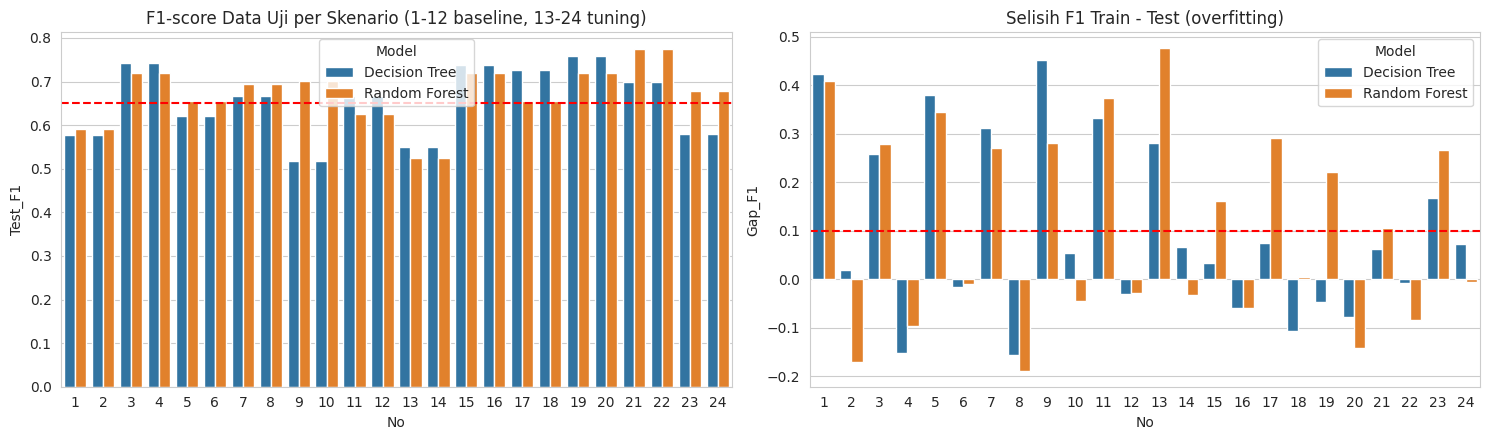

,tidak,ya (Grid Search),tidak,ya (Random OverSampling),ya (class_weight=balanced),tidak,ya (5 fitur baru),5-fold,tidak
Model,,,,,,,,,
Decision Tree,0.632,0.675,0.659,0.660,0.623,0.671,0.635,0.653,0.653
Random Forest,0.664,0.679,0.644,0.722,0.652,0.661,0.682,0.671,0.671


In [13]:
# ============ 13. VISUALISASI PERBANDINGAN SKENARIO ============
fig, ax = plt.subplots(1,2, figsize=(15,4.5))
sns.barplot(data=res, x='No', y='Test_F1', hue='Model', ax=ax[0]); ax[0].set_title('F1-score Data Uji per Skenario (1-12 baseline, 13-24 tuning)'); ax[0].axhline(0.65, ls='--', c='r')
res['Gap_F1'] = res.Train_F1 - res.Test_F1
sns.barplot(data=res, x='No', y='Gap_F1', hue='Model', ax=ax[1]); ax[1].set_title('Selisih F1 Train - Test (overfitting)'); ax[1].axhline(0.10, ls='--', c='r')
plt.tight_layout(); plt.show()

# rata-rata pengaruh tiap perlakuan terhadap F1 uji
eff = pd.concat([res.groupby(['Model','Tuning']).Test_F1.mean().unstack(), res.groupby(['Model','DataBalancing']).Test_F1.mean().unstack(),
                 res.groupby(['Model','FeatureEngineering']).Test_F1.mean().unstack(), res.groupby(['Model','CrossValidation']).Test_F1.mean().unstack()], axis=1)
display(eff.round(3))

**Cara membaca:** grafik kiri — batang di atas garis merah putus-putus (0.65) memenuhi kriteria F1. Grafik kanan — batang di atas garis merah (0.10) berarti overfitting. Tabel rata-rata menunjukkan perlakuan mana (tuning, balancing, FE, CV) yang rata-rata menaikkan F1 uji.

In [14]:
# ============ 14. PEMILIHAN MODEL TERBAIK & UJI KRITERIA ============
# Pemilihan memakai skor training 5-fold CV (bukan data uji) agar objektif; data uji hanya untuk laporan akhir.
cand = res[res.CrossValidation=='5-fold']
best = {m: cand[cand.Model==m].sort_values('Train_F1', ascending=False).iloc[0] for m in cand.Model.unique()}
bt = pd.DataFrame(best).T[['Model','No','FeatureSelection','DataBalancing','Tuning','BestParams','Train_F1','Test_Acc','Test_Prec','Test_Rec','Test_F1','Gap_F1']]
bt['Lolos kriteria'] = [(r.Test_Acc>=.75 and r.Test_Rec>=.65 and r.Test_F1>=.65 and r.Gap_F1<=.10) for r in bt.itertuples()]
display(bt)

,Model,No,FeatureSelection,DataBalancing,Tuning,BestParams,Train_F1,Test_Acc,Test_Prec,Test_Rec,Test_F1,Gap_F1,Lolos kriteria
Decision Tree,Decision Tree,22,"ya (SelectKBest MI, k=10)",ya (Random OverSampling),ya (Grid Search),"{'criterion': 'gini', 'max_depth': 7, 'min_sam...",0.692308,0.814433,0.677419,0.724138,0.7,-0.007692,True
Random Forest,Random Forest,22,"ya (SelectKBest MI, k=10)",ya (Random OverSampling),ya (Grid Search),"{'max_depth': 8, 'min_samples_leaf': 3, 'n_est...",0.690265,0.85567,0.727273,0.827586,0.774194,-0.083928,True


**Cara membaca:** satu model terbaik per algoritma. `Lolos kriteria = True` jika Accuracy ≥ 0.75, Recall ≥ 0.65, F1 ≥ 0.65 dan Gap ≤ 0.10 (kriteria Soal 03).

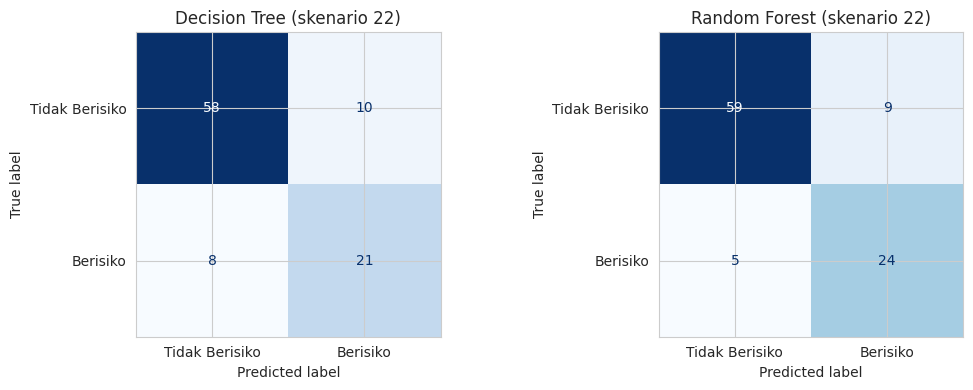

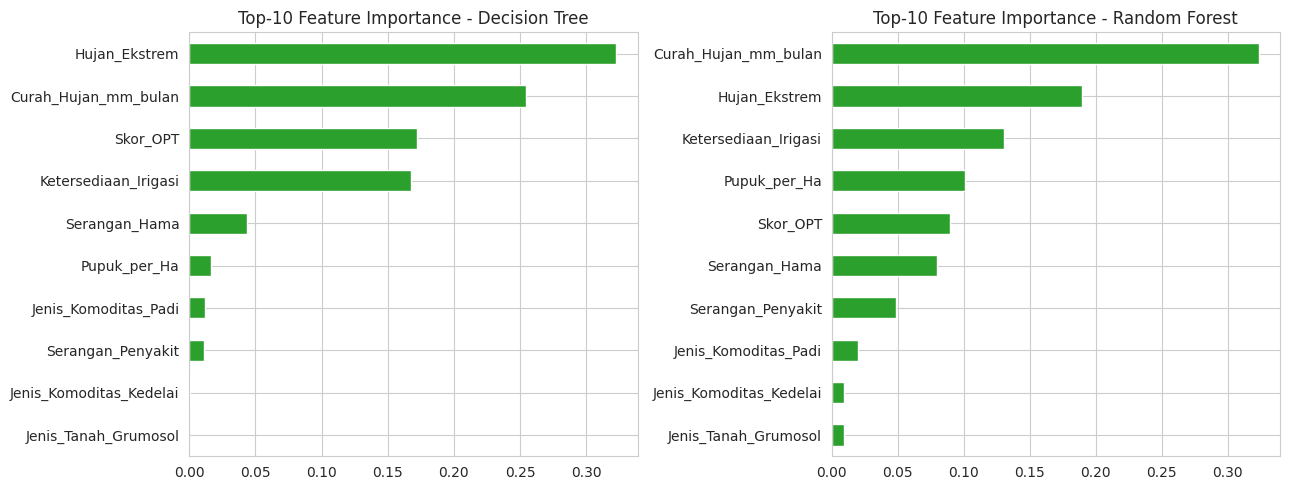

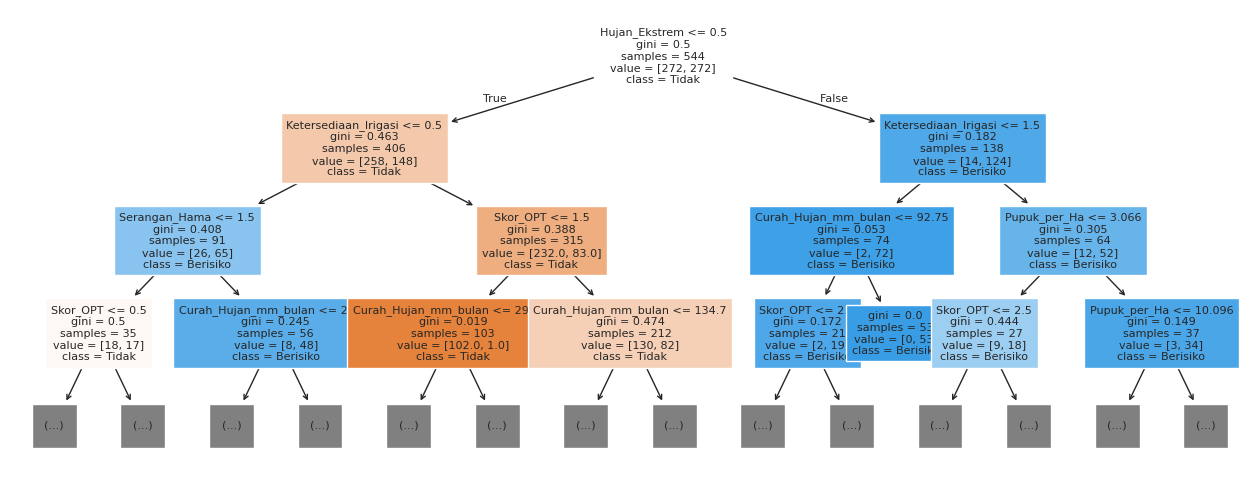

In [15]:
# ============ 15. CONFUSION MATRIX, FEATURE IMPORTANCE, POHON KEPUTUSAN ============
fig, ax = plt.subplots(1,2, figsize=(11,4))
for a,(m,r) in zip(ax, best.items()):
    key = ('DT' if m=='Decision Tree' else 'RF', int(r.No)); mdl = models[key]
    ConfusionMatrixDisplay(confusion_matrix(yte, mdl.predict(Xte)), display_labels=['Tidak Berisiko','Berisiko']).plot(ax=a, cmap='Blues', colorbar=False)
    a.set_title(f'{m} (skenario {key[1]})')
plt.tight_layout(); plt.show()

# feature importance model terbaik (rata-rata kedua algoritma ditampilkan terpisah)
fig, ax = plt.subplots(1,2, figsize=(13,5))
for a,(m,r) in zip(ax, best.items()):
    mdl = models[('DT' if m=='Decision Tree' else 'RF', int(r.No))]
    pd.Series(mdl.m.feature_importances_, index=mdl.keep).sort_values().tail(10).plot.barh(ax=a, color='tab:green'); a.set_title(f'Top-10 Feature Importance - {m}')
plt.tight_layout(); plt.show()

# visualisasi pohon keputusan (kedalaman 3 teratas)
dt = models[('DT', int(best['Decision Tree'].No))]
plt.figure(figsize=(16,6)); plot_tree(dt.m, feature_names=dt.keep, class_names=['Tidak','Berisiko'], max_depth=3, filled=True, fontsize=8); plt.show()

**Cara membaca:**
- *Confusion matrix*: baris = kelas sebenarnya, kolom = prediksi. Sel kanan-bawah = lahan berisiko yang terdeteksi benar (TP); kiri-bawah = berisiko tapi terlewat (FN, paling merugikan); kanan-atas = alarm palsu (FP).
- *Feature importance*: batang terpanjang = faktor paling menentukan prediksi; bandingkan dengan hipotesis awal H1–H4.
- *Pohon keputusan*: baca dari akar; `gini` = ketidakmurnian, `samples` = jumlah data, `class` = kelas dominan di simpul. Pertanyaan di tiap simpul adalah aturan if-then yang dapat dijelaskan ke penyuluh.

In [16]:
# ============ 16. REVIEW PROSES (kesesuaian dengan rencana Soal 03) ============
print('Jumlah skenario dijalankan   :', len(res), '(24 per algoritma, 2 algoritma)')
print('Split 80:20 stratified       : ya | 5-fold CV: ya | baseline & Grid Search: ya')
print('Preprocessing di-fit di train : ya (Prep/Pipe di-fit hanya pada data latih/fold-latih) -> tanpa data leakage')
print('Skenario lolos kriteria      :', int(((res.Test_Acc>=.75)&(res.Test_Rec>=.65)&(res.Test_F1>=.65)&(res.Gap_F1<=.10)).sum()), 'dari', len(res))
print('Rata-rata F1 uji: baseline =', res[res.Tuning=='tidak'].Test_F1.mean().round(3), '| tuning =', res[res.Tuning!='tidak'].Test_F1.mean().round(3))

Jumlah skenario dijalankan   : 48 (24 per algoritma, 2 algoritma)
Split 80:20 stratified       : ya | 5-fold CV: ya | baseline & Grid Search: ya
Preprocessing di-fit di train : ya (Prep/Pipe di-fit hanya pada data latih/fold-latih) -> tanpa data leakage
Skenario lolos kriteria      : 13 dari 48
Rata-rata F1 uji: baseline = 0.648 | tuning = 0.677


**Cara membaca:** ringkasan kepatuhan pelaksanaan terhadap skenario. Bandingkan rata-rata F1 baseline vs tuning untuk menilai manfaat optimasi hyperparameter. Gunakan angka ini pada slide *Kesimpulan*.